# 01 — Simulazione e validazione

**Scopo.** Generare le serie di moto browniano frazionario (fBm) che useremo come *verità nota* per
tutti gli approcci, e **verificare che la simulazione sia corretta** prima di fidarci dei parametri veri.
Verifichiamo anche lo strumento che costruisce i grafi di visibilità, perché gli approcci 2 e 4 ne dipendono.

**Contenuto**
1. Configurazione
2. Metodo di simulazione (Davies–Harte) ed esempi di traiettorie
3. Validazione della simulazione: autovalori, autocovarianza del fGn, legge di scala del fBm
4. Validazione dei grafi di visibilità: confronto con la definizione, distribuzione esatta del grado
   dell'HVG per rumore i.i.d., invarianze
5. Costruzione e salvataggio del dataset (train / validation / test + set di robustezza)
6. Riepilogo e decisioni

Notazione degli appunti di Econofisica (par. 6.1): $W_H(t)$ è il fBm,
$dW_H(t) = W_H(t+1) - W_H(t)$ il rumore gaussiano frazionario (fGn).

In [1]:
# --- Setup: su Colab clona il repository; ovunque installa ciò che manca ---
import os, sys, subprocess, importlib.util

IN_COLAB = "google.colab" in sys.modules
REPO_URL = "https://github.com/Arminas00/stochastic-ml.git"
if IN_COLAB:
    repo = "/content/stochastic-ml"
    if os.path.exists(repo):
        subprocess.run(["git", "-C", repo, "pull", "-q"], check=True)
    else:
        subprocess.run(["git", "clone", "-q", REPO_URL, repo], check=True)
    os.chdir(repo)

needed = ["numpy", "scipy", "pandas", "matplotlib", "sklearn", "ts2vg"]
missing = [m for m in needed if importlib.util.find_spec(m) is None]
if missing:
    print("Installo:", missing)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)
sys.path.insert(0, os.getcwd())
print("Cartella di lavoro:", os.getcwd(), "| Colab:", IN_COLAB)

Cartella di lavoro: C:\Users\user\Downloads\AI_Project\stochastic-ml | Colab: False


## 1. Configurazione

`MODE = "quick"` gira su CPU in pochi minuti (verifica che tutto funzioni);
`MODE = "full"` produce il dataset definitivo (vedi D-03 nel registro delle decisioni).
Tutti i numeri casuali derivano da `SEED`.

In [2]:
MODE = "quick"          # "quick" (CPU, verifica) oppure "full" (dataset definitivo)
SEED = 2026             # seed principale: gli split usano SEED, SEED+1, SEED+2
DATA_DIR = "data"       # dati generati (non versionati: si rigenerano dai seed)
FIG_DIR = "figures"     # figure salvate per la relazione finale

# Numero di serie usate nelle verifiche (indipendenti dal dataset)
N_CHECK_SERIES = 2000 if MODE == "quick" else 5000

In [3]:
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

import sp_utils as u

u.set_seed(SEED)
Path(FIG_DIR).mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

def savefig(name):
    plt.savefig(f"{FIG_DIR}/01_{name}.png", bbox_inches="tight", dpi=150)

CFG = u.MODES[MODE]
print("Modalità:", MODE, CFG)

CHECKS = []   # (verifica, valore, soglia, esito) — riassunte alla fine
def check(name, value, threshold, passed):
    CHECKS.append((name, value, threshold, "OK" if passed else "FALLITA"))
    print(("OK      " if passed else "FALLITA ") + f"{name}: {value}  (soglia {threshold})")

Modalità: quick {'N': 512, 'n_train': 4000, 'n_val': 1000, 'n_test': 2000, 'robust_lengths': (128, 256, 1024, 2048), 'n_robust': 500}


## 2. Metodo di simulazione

Il fGn è un processo gaussiano stazionario con autocovarianza (appunti, par. 6.1)

$$\gamma(h) = \langle dW_H(t+h)\, dW_H(t)\rangle = \tfrac12\left[|h+1|^{2H} - 2|h|^{2H} + |h-1|^{2H}\right].$$

Usiamo il **metodo di Davies–Harte (embedding circolante)**: la matrice di covarianza di Toeplitz $N\times N$
si immerge in una matrice circolante $2N\times 2N$, che si diagonalizza con la FFT. Se i suoi autovalori
$\lambda_k$ sono tutti $\ge 0$, la serie

$$y = \mathrm{FFT}\!\left(\sqrt{\lambda/2N}\; z\right),\qquad z_k = a_k + i b_k,\; a_k, b_k \sim \mathcal N(0,1),$$

ha parte reale con covarianza **esattamente** $\gamma$: il metodo è esatto, non approssimato, e costa $O(N\log N)$.
Il fBm si ottiene come somma cumulata: $W_H(0)=0$, $W_H(t) = \sum_{s<t} dW_H(s)$.

Perché questo metodo e non altri: vedi **D-13** nel registro.

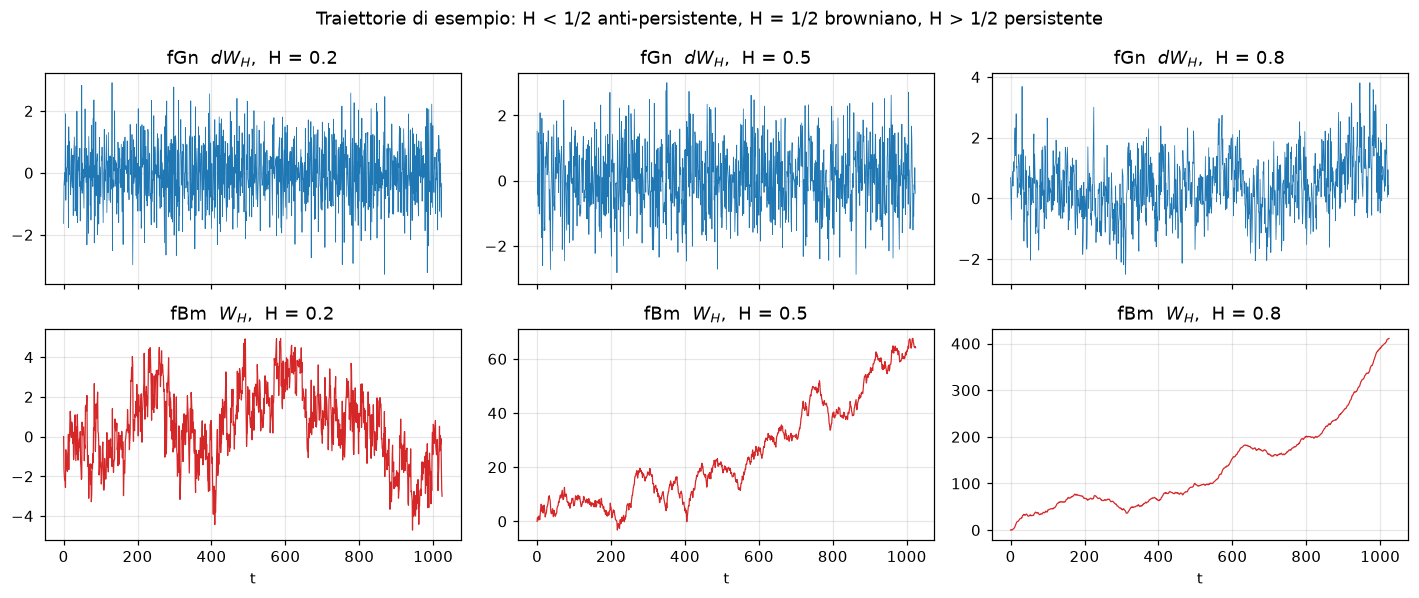

In [4]:
rng = np.random.default_rng(SEED)
N_demo = 1024
fig, axes = plt.subplots(2, 3, figsize=(13, 5.5), sharex=True)
for j, H in enumerate([0.2, 0.5, 0.8]):
    x = u.simulate_fgn(N_demo, [H], rng)[0]
    axes[0, j].plot(x, lw=0.5, color="C0")
    axes[0, j].set_title(f"fGn  $dW_H$,  H = {H}")
    axes[1, j].plot(u.fbm_from_fgn(x), lw=0.8, color="C3")
    axes[1, j].set_title(f"fBm  $W_H$,  H = {H}")
    axes[1, j].set_xlabel("t")
fig.suptitle("Traiettorie di esempio: H < 1/2 anti-persistente, H = 1/2 browniano, H > 1/2 persistente")
plt.tight_layout(); savefig("traiettorie"); plt.show()

## 3. Validazione della simulazione

Prima di usare le serie come verità nota controlliamo tre risultati esatti.

**3a. Autovalori dell'embedding circolante.** Devono essere tutti $\ge 0$ per ogni $H$ e ogni $N$ usati,
altrimenti il metodo non è esatto.

In [5]:
H_grid = np.linspace(0.01, 0.99, 99)
worst = []
for n in sorted({CFG["N"], *CFG["robust_lengths"], 4096}):
    lam = u.davies_harte_eigenvalues(n, H_grid)
    worst.append((n, (lam.min(axis=1) / lam.max(axis=1)).min()))
    print(f"N = {n:5d}:  min_H  min(lambda)/max(lambda) = {worst[-1][1]:.2e}")
check("autovalori Davies-Harte >= 0 (tutti H, tutti N)", f"{min(w for _, w in worst):.1e}", ">= 0",
      min(w for _, w in worst) >= 0)

N =   128:  min_H  min(lambda)/max(lambda) = 7.43e-05
N =   256:  min_H  min(lambda)/max(lambda) = 3.77e-05
N =   512:  min_H  min(lambda)/max(lambda) = 1.91e-05
N =  1024:  min_H  min(lambda)/max(lambda) = 9.71e-06
N =  2048:  min_H  min(lambda)/max(lambda) = 4.92e-06
N =  4096:  min_H  min(lambda)/max(lambda) = 2.50e-06
OK      autovalori Davies-Harte >= 0 (tutti H, tutti N): 2.5e-06  (soglia >= 0)


**3b. Autocovarianza del fGn.** Per diversi $H$ simuliamo molte serie indipendenti e confrontiamo
l'autocovarianza campionaria con $\gamma(h)$. L'errore standard viene dalla dispersione *tra serie*
(che sono indipendenti), quindi lo scarto normalizzato $z = (\hat\gamma - \gamma)/\mathrm{SE}$
deve essere compatibile con una $\mathcal N(0,1)$. Soglia: $\max|z| < 4$ su tutti i lag e tutti gli $H$
(con ~100 confronti, $|z|>4$ ha probabilità ~0.6% se la simulazione è corretta).

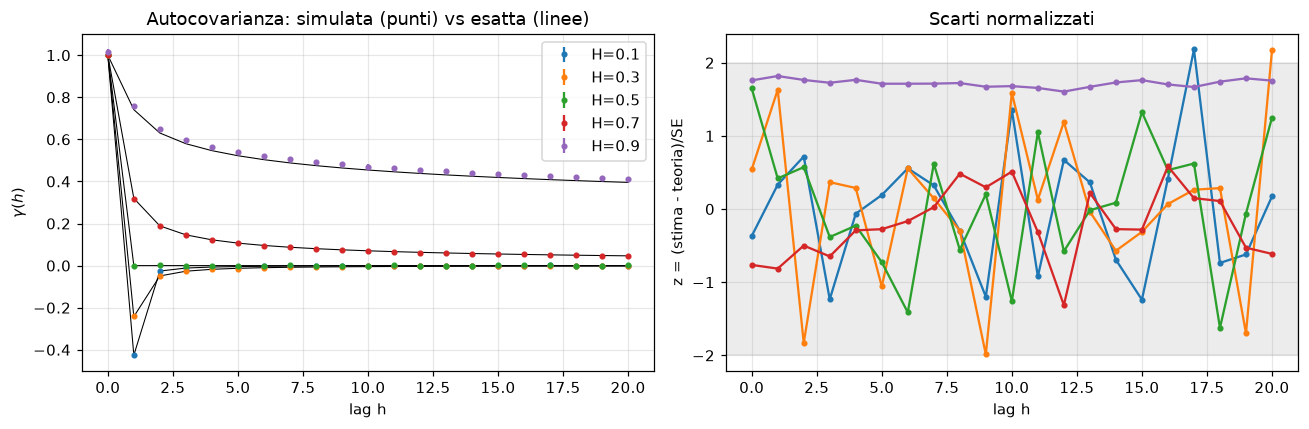

,H,var. campionaria,gamma(1) stimata,gamma(1) teorica,max |z|
0,0.1,0.9994,-0.4253,-0.4257,2.1811
1,0.3,1.0008,-0.2405,-0.2421,2.1681
2,0.5,1.0024,0.0004,0.0000,1.6495
3,0.7,0.9987,0.3183,0.3195,1.3139
4,0.9,1.0173,0.7590,0.7411,1.8181


OK      autocovarianza fGn: max|z| su lag 0-20 e 5 valori di H: 2.18  (soglia < 4)


In [6]:
MAX_LAG = 20
rows, zs = [], []
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for H in [0.1, 0.3, 0.5, 0.7, 0.9]:
    x = u.simulate_fgn(CFG["N"], np.full(N_CHECK_SERIES, H), rng)
    est, se = u.sample_autocov(x, MAX_LAG)
    th = u.fgn_autocov(np.arange(MAX_LAG + 1), H)
    z = (est - th) / se
    zs.append(np.abs(z).max())
    rows.append({"H": H, "var. campionaria": est[0], "gamma(1) stimata": est[1],
                 "gamma(1) teorica": th[1], "max |z|": np.abs(z).max()})
    h = np.arange(MAX_LAG + 1)
    ax[0].errorbar(h, est, yerr=se, fmt="o", ms=3, label=f"H={H}")
    ax[0].plot(h, th, "k-", lw=0.7)
    ax[1].plot(h, z, "o-", ms=3, label=f"H={H}")
ax[0].set(xlabel="lag h", ylabel=r"$\gamma(h)$", title="Autocovarianza: simulata (punti) vs esatta (linee)")
ax[1].axhspan(-2, 2, color="grey", alpha=0.15)
ax[1].set(xlabel="lag h", ylabel="z = (stima - teoria)/SE", title="Scarti normalizzati")
ax[0].legend(); plt.tight_layout(); savefig("autocovarianza"); plt.show()
display(pd.DataFrame(rows).round(4))
check("autocovarianza fGn: max|z| su lag 0-20 e 5 valori di H", f"{max(zs):.2f}", "< 4", max(zs) < 4)

**3c. Legge di scala del fBm.** Dagli appunti $\langle W_H^2(t)\rangle = t^{2H}$.
Stimiamo la varianza d'insieme $\widehat{\mathrm{Var}}[W_H(t)]$ e la pendenza in scala bilogaritmica,
che deve valere $2H$. Controlliamo anche che il rapporto $\widehat{\mathrm{Var}}/t^{2H}$ sia compatibile con 1.

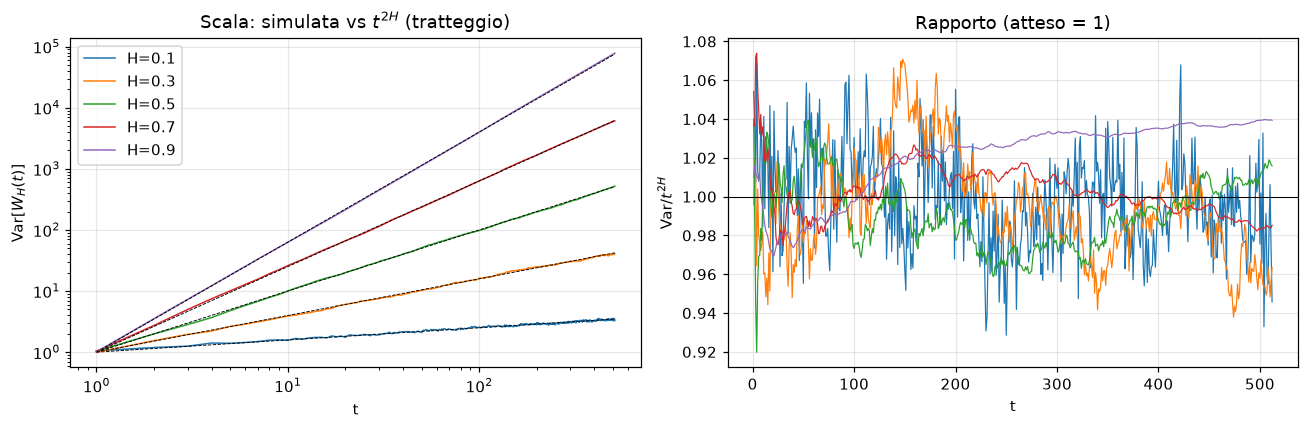

,H,pendenza stimata,2H,scarto,intercetta (attesa 0),max |z| di Var/t^2H
0,0.1,0.1914,0.2,-0.0086,0.0430,2.4764
1,0.3,0.5965,0.6,-0.0035,0.0126,2.1015
2,0.5,0.9967,1.0,-0.0033,0.0082,2.7656
3,0.7,1.3959,1.4,-0.0041,0.0240,2.2062
4,0.9,1.8164,1.8,0.0164,-0.0657,1.1279


OK      fBm: |pendenza - 2H| (max su 5 valori di H): 0.0164  (soglia < 0.05)
OK      fBm: max|z| di Var[W_H(t)] - t^2H (tutti t): 2.77  (soglia < 5)


In [7]:
rows = []
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
t = np.arange(1, CFG["N"] + 1)
ratio_z = []
for H in [0.1, 0.3, 0.5, 0.7, 0.9]:
    W = u.fbm_from_fgn(u.simulate_fgn(CFG["N"], np.full(N_CHECK_SERIES, H), rng))[:, 1:]
    var = (W ** 2).mean(axis=0)                              # media nota = 0
    se_var = (W ** 2).std(axis=0, ddof=1) / np.sqrt(len(W))
    slope, intercept = np.polyfit(np.log(t), np.log(var), 1)
    zr = (var - t ** (2 * H)) / se_var
    ratio_z.append(np.abs(zr).max())
    rows.append({"H": H, "pendenza stimata": slope, "2H": 2 * H, "scarto": slope - 2 * H,
                 "intercetta (attesa 0)": intercept, "max |z| di Var/t^2H": np.abs(zr).max()})
    ax[0].loglog(t, var, lw=1, label=f"H={H}")
    ax[0].loglog(t, t ** (2 * H), "k--", lw=0.6)
    ax[1].plot(t, var / t ** (2 * H), lw=0.8, label=f"H={H}")
ax[0].set(xlabel="t", ylabel=r"Var$[W_H(t)]$", title=r"Scala: simulata vs $t^{2H}$ (tratteggio)")
ax[1].axhline(1, color="k", lw=0.7)
ax[1].set(xlabel="t", ylabel=r"Var$/t^{2H}$", title="Rapporto (atteso = 1)")
ax[0].legend(); plt.tight_layout(); savefig("scala_fbm"); plt.show()
df_scala = pd.DataFrame(rows).round(4); display(df_scala)
# La pendenza è un controllo visivo/indicativo (per H grande le varianze a tempi diversi sono molto
# correlate e il fit è rumoroso); il controllo rigoroso è quello su z, punto per punto.
check("fBm: |pendenza - 2H| (max su 5 valori di H)", f"{df_scala['scarto'].abs().max():.4f}", "< 0.05",
      df_scala["scarto"].abs().max() < 0.05)
check("fBm: max|z| di Var[W_H(t)] - t^2H (tutti t)", f"{max(ratio_z):.2f}", "< 5", max(ratio_z) < 5)

*Nota.* La soglia su $|z|$ è qui 5 invece di 4 perché si confrontano $N$ tempi diversi (fino a 1024),
non 20 lag: con più confronti il massimo di $|z|$ è naturalmente più alto. I valori in $t$ diversi sono inoltre
fortemente correlati (stessa traiettoria), quindi non sono confronti indipendenti.

## 4. Validazione dei grafi di visibilità

Usiamo la libreria `ts2vg`. Ogni punto $(t, x_t)$ della serie è un nodo; due nodi sono collegati se
"si vedono" (Lacasa et al. 2008, Luque et al. 2009):

- **NVG (naturale):** $i<j$ collegati se $x_k < x_j + (x_i - x_j)\frac{j-k}{j-i}$ per ogni $i<k<j$
  (nessun punto intermedio sopra la retta che li congiunge);
- **HVG (orizzontale):** $i<j$ collegati se $x_k < \min(x_i, x_j)$ per ogni $i<k<j$.

Un esempio su 20 punti:

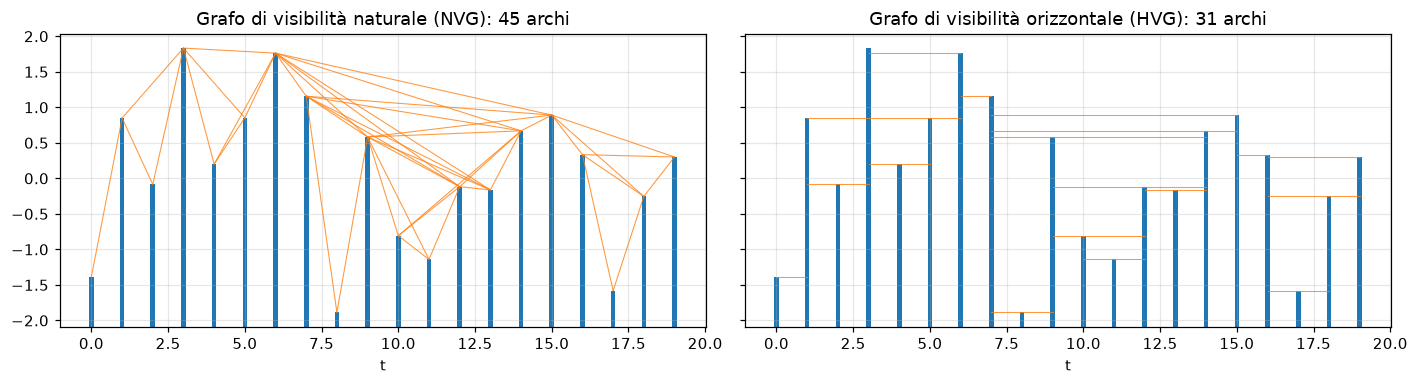

In [8]:
x_demo = np.random.default_rng(SEED + 7).standard_normal(20)
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6), sharey=True)
for ax, kind, title in [(axes[0], "nvg", "Grafo di visibilità naturale (NVG)"),
                        (axes[1], "hvg", "Grafo di visibilità orizzontale (HVG)")]:
    edges, deg = u.visibility_graph(x_demo, kind)
    for i, j in edges:
        if kind == "nvg":
            ax.plot([i, j], [x_demo[i], x_demo[j]], color="C1", lw=0.7, alpha=0.8)
        else:
            y = min(x_demo[i], x_demo[j])
            ax.plot([i, j], [y, y], color="C1", lw=0.7, alpha=0.8)
    ax.bar(range(20), x_demo - x_demo.min() + 0.2, bottom=x_demo.min() - 0.2, width=0.15, color="C0")
    ax.set(title=f"{title}: {len(edges)} archi", xlabel="t")
plt.tight_layout(); savefig("esempio_grafi"); plt.show()

**4a. `ts2vg` contro la definizione.** Confrontiamo gli archi prodotti da `ts2vg` con un'implementazione
diretta della definizione (lenta, $O(N^3)$) su serie corte di rumore e di fBm con vari $H$.
Devono coincidere esattamente.

In [9]:
n_ok = n_tot = 0
rng_g = np.random.default_rng(SEED + 11)
for H in [0.1, 0.5, 0.9]:
    for _ in range(10):
        x = u.fbm_from_fgn(u.simulate_fgn(80, [H], rng_g))[0]
        for kind in ["nvg", "hvg"]:
            e, _ = u.visibility_graph(x, kind)
            n_ok += {tuple(sorted(p)) for p in e.tolist()} == u.visibility_edges_bruteforce(x, kind)
            n_tot += 1
check("ts2vg = definizione (NVG e HVG, 60 grafi di fBm, N=81)", f"{n_ok}/{n_tot}", "tutti", n_ok == n_tot)

OK      ts2vg = definizione (NVG e HVG, 60 grafi di fBm, N=81): 60/60  (soglia tutti)


**4b. Distribuzione esatta del grado dell'HVG per rumore i.i.d.** Per qualunque rumore i.i.d. continuo
(Luque et al. 2009)

$$P(k) = \frac13\left(\frac23\right)^{k-2},\qquad k\ge2,\qquad \langle k\rangle = 4 \;(N\to\infty).$$

Il risultato è *universale*: non dipende dalla distribuzione del rumore. Lo verifichiamo con rumore gaussiano
e uniforme. Per $N$ finito il grado medio esatto (con i bordi) è
$\langle k\rangle_N = \frac{2}{N}\sum_{d=1}^{N-1}(N-d)\frac{2}{d(d+1)}$, perché due nodi a distanza $d$
si vedono se e solo se sono i due valori più alti tra i $d+1$ coinvolti (probabilità $2/[d(d+1)]$).
Gli errori standard vengono dalla dispersione tra serie indipendenti.

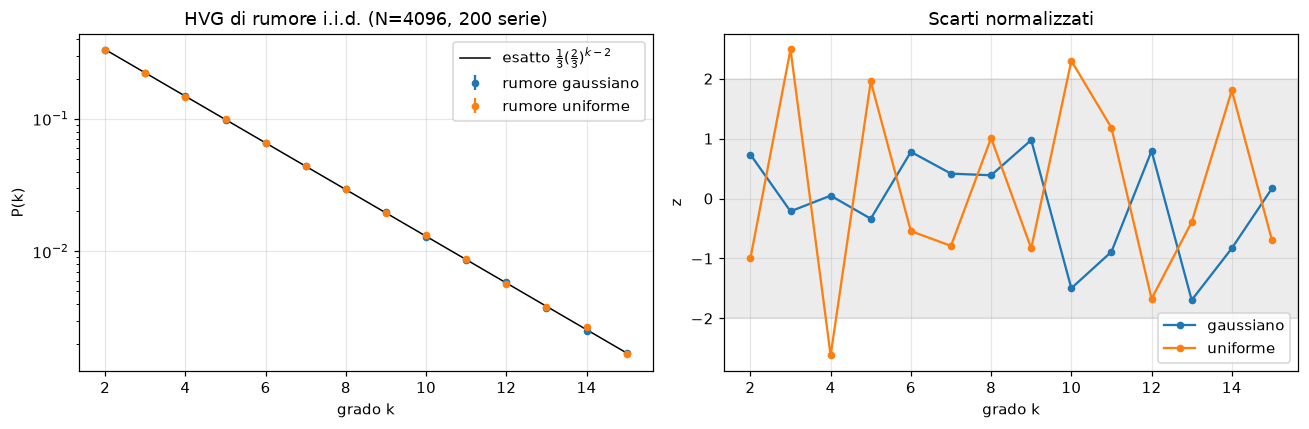

,rumore,"max |z| P(k), k=2..15",<k> stimato,<k> esatto (N finito),z di <k>
0,gaussiano,1.6942,3.9912,3.9913,-0.9844
1,uniforme,2.6166,3.9913,3.9913,0.0008


OK      HVG i.i.d.: max|z| di P(k) (gauss. e unif.): 2.62  (soglia < 4)
OK      HVG i.i.d.: max|z| di <k> vs formula esatta: 0.98  (soglia < 4)


In [10]:
N_HVG, N_SER = 4096, 200
k_vals = np.arange(2, 16)
rng_h = np.random.default_rng(SEED + 13)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
rows = []
for name, sampler in [("gaussiano", lambda: rng_h.standard_normal(N_HVG)),
                      ("uniforme", lambda: rng_h.uniform(size=N_HVG))]:
    pk, kmean = [], []
    for _ in range(N_SER):
        _, deg = u.visibility_graph(sampler(), "hvg")
        pk.append([(deg == k).mean() for k in k_vals]); kmean.append(deg.mean())
    pk = np.array(pk); m, se = pk.mean(0), pk.std(0, ddof=1) / np.sqrt(N_SER)
    th = u.hvg_degree_pmf_iid(k_vals)
    z = (m - th) / se
    km, kse, kth = np.mean(kmean), np.std(kmean, ddof=1) / np.sqrt(N_SER), u.hvg_mean_degree_iid(N_HVG)
    rows.append({"rumore": name, "max |z| P(k), k=2..15": np.abs(z).max(),
                 "<k> stimato": km, "<k> esatto (N finito)": kth, "z di <k>": (km - kth) / kse})
    ax[0].errorbar(k_vals, m, yerr=se, fmt="o", ms=4, label=f"rumore {name}")
    ax[1].plot(k_vals, z, "o-", ms=4, label=name)
ax[0].semilogy(k_vals, th, "k-", lw=1, label=r"esatto $\frac{1}{3}(\frac{2}{3})^{k-2}$")
ax[0].set(xlabel="grado k", ylabel="P(k)", title=f"HVG di rumore i.i.d. (N={N_HVG}, {N_SER} serie)")
ax[1].axhspan(-2, 2, color="grey", alpha=0.15)
ax[1].set(xlabel="grado k", ylabel="z", title="Scarti normalizzati")
ax[0].legend(); ax[1].legend(); plt.tight_layout(); savefig("hvg_iid"); plt.show()
df_hvg = pd.DataFrame(rows).round(4); display(df_hvg)
check("HVG i.i.d.: max|z| di P(k) (gauss. e unif.)", f"{df_hvg['max |z| P(k), k=2..15'].max():.2f}", "< 4",
      df_hvg["max |z| P(k), k=2..15"].max() < 4)
check("HVG i.i.d.: max|z| di <k> vs formula esatta", f"{df_hvg['z di <k>'].abs().max():.2f}", "< 4",
      df_hvg["z di <k>"].abs().max() < 4)

**4c. Invarianze.** È il punto fisico chiave del progetto, quindi lo verifichiamo invece di assumerlo.

- La NVG dipende solo da quali punti stanno sopra o sotto le rette che congiungono altri punti.
  Una trasformazione affine $x_t \to a\,x_t + b\,t + c$ con $a>0$ manda rette in rette e conserva
  il "sopra/sotto": **la NVG è invariante per riscalamento, traslazione e trend lineare.**
- La HVG dipende solo dall'ordinamento dei valori: **è invariante per qualunque trasformazione monotona
  crescente** (anche non lineare), **ma non per un trend lineare**, che cambia l'ordinamento.

Conseguenza attesa: i grafi non vedono l'ampiezza di una serie (es. la $\sigma$ di un OU, il livello di
volatilità), né la deriva di un moto browniano (solo NVG). Applichiamo le trasformazioni a 100 traiettorie
di fBm e misuriamo la frazione di grafi rimasti identici e la similarità di Jaccard media degli archi.

In [11]:
def edge_set(x, kind):
    e, _ = u.visibility_graph(x, kind)
    return {tuple(sorted(p)) for p in e.tolist()}

rng_i = np.random.default_rng(SEED + 17)
n_inv, L = 100, 512
tt = np.arange(L + 1)
transforms = {
    "riscalamento  3.7 x + 10":        lambda x: 3.7 * x + 10,
    "trend lineare x + b t":           lambda x: x + 2 * x.std() / L * tt,
    "affine completa 0.3 x - b t + 5": lambda x: 0.3 * x - 2 * x.std() / L * tt + 5,
    "monotona non lineare exp(x/s)":   lambda x: np.exp(x / x.std()),
}
res = {name: {"nvg": [], "hvg": []} for name in transforms}
for _ in range(n_inv):
    x = u.fbm_from_fgn(u.simulate_fgn(L, rng_i.uniform(0.1, 0.9, 1), rng_i))[0]
    for kind in ["nvg", "hvg"]:
        e0 = edge_set(x, kind)
        for name, f in transforms.items():
            e1 = edge_set(f(x), kind)
            res[name][kind].append((e0 == e1, len(e0 & e1) / len(e0 | e1)))
rows = []
for name in transforms:
    r = {"trasformazione": name}
    for kind in ["nvg", "hvg"]:
        a = np.array(res[name][kind])
        r[f"{kind.upper()}: grafi identici"] = f"{a[:, 0].mean():.0%}"
        r[f"{kind.upper()}: Jaccard medio"] = round(a[:, 1].mean(), 4)
    rows.append(r)
df_inv = pd.DataFrame(rows); display(df_inv)

,trasformazione,NVG: grafi identici,NVG: Jaccard medio,HVG: grafi identici,HVG: Jaccard medio
0,riscalamento 3.7 x + 10,100%,1.0000,100%,1.0000
1,trend lineare x + b t,100%,1.0000,0%,0.8243
2,affine completa 0.3 x - b t + 5,100%,1.0000,0%,0.7275
3,monotona non lineare exp(x/s),0%,0.6329,100%,1.0000


In [12]:
def frac_identical(name, kind):
    return np.mean([s for s, _ in res[name][kind]])

check("NVG invariante per riscalamento, trend, affine",
      f"{min(frac_identical(n, 'nvg') for n in list(transforms)[:3]):.0%}", "~100%",
      min(frac_identical(n, "nvg") for n in list(transforms)[:3]) >= 0.97)
check("HVG invariante per riscalamento e trasformazione monotona",
      f"{min(frac_identical(list(transforms)[i], 'hvg') for i in (0, 3)):.0%}", "100%",
      min(frac_identical(list(transforms)[i], "hvg") for i in (0, 3)) == 1.0)
check("HVG NON invariante per trend lineare (atteso: cambia)",
      f"{frac_identical(list(transforms)[1], 'hvg'):.0%} identici", "< 50%",
      frac_identical(list(transforms)[1], "hvg") < 0.5)
check("NVG NON invariante per trasformazione monotona non lineare",
      f"{frac_identical(list(transforms)[3], 'nvg'):.0%} identici", "< 50%",
      frac_identical(list(transforms)[3], "nvg") < 0.5)

OK      NVG invariante per riscalamento, trend, affine: 100%  (soglia ~100%)
OK      HVG invariante per riscalamento e trasformazione monotona: 100%  (soglia 100%)
OK      HVG NON invariante per trend lineare (atteso: cambia): 0% identici  (soglia < 50%)
OK      NVG NON invariante per trasformazione monotona non lineare: 0% identici  (soglia < 50%)


*Perché "~100%" e non "100%" per la NVG.* Il criterio della NVG confronta numeri reali con una retta: se un punto
intermedio è quasi esattamente sulla retta, l'arrotondamento in virgola mobile dopo la trasformazione può
cambiare l'esito. Contiamo quindi anche la similarità di Jaccard, che deve restare praticamente 1. L'HVG usa
solo confronti tra valori, per cui le trasformazioni monotone la lasciano esattamente invariata.

## 5. Costruzione del dataset

- $H \sim \mathcal U(0.05, 0.95)$ (D-10), una serie per valore di $H$.
- Salviamo il **fGn** (float32); il fBm si ottiene con la somma cumulata. È la stessa informazione
  (corrispondenza biunivoca), quindi ogni approccio può ricevere la rappresentazione più naturale per lui (D-14).
- Tre split generati con **seed diversi e indipendenti** (D-15): train (per addestrare), validation
  (solo early stopping e scelta degli iperparametri), test (solo per i numeri finali).
- Set di test aggiuntivi a **lunghezze diverse** per le prove di robustezza (D-16).

In [13]:
t0 = time.time()
ds = u.load_or_make_fbm_dataset(MODE, SEED, DATA_DIR)
print(f"Dataset pronto in {time.time() - t0:.1f} s")
summary = pd.DataFrame([{"split": s, "serie": len(d["H"]), "lunghezza N": d["X"].shape[1],
                         "H min": d["H"].min(), "H max": d["H"].max(), "H medio": d["H"].mean(),
                         "MB": d["X"].nbytes / 1e6} for s, d in ds.items()]).round(3)
display(summary)

Dataset pronto in 0.1 s


,split,serie,lunghezza N,H min,H max,H medio,MB
0,train,4000,512,0.051,0.950,0.502,8.192
1,val,1000,512,0.050,0.950,0.504,2.048
2,test,2000,512,0.051,0.950,0.502,4.096
3,test_N128,500,128,0.052,0.950,0.486,0.256
4,test_N256,500,256,0.052,0.950,0.497,0.512
5,test_N1024,500,1024,0.051,0.949,0.517,2.048
6,test_N2048,500,2048,0.050,0.950,0.494,4.096


OK      nessuna serie in comune tra train/val/test: 0  (soglia 0)
OK      H uniforme in ogni split (test KS, p minimo): 0.721  (soglia > 0.001)
OK      fGn a varianza unitaria: media di <x^2> sul train: 0.9978  (soglia 1 ± 0.02)


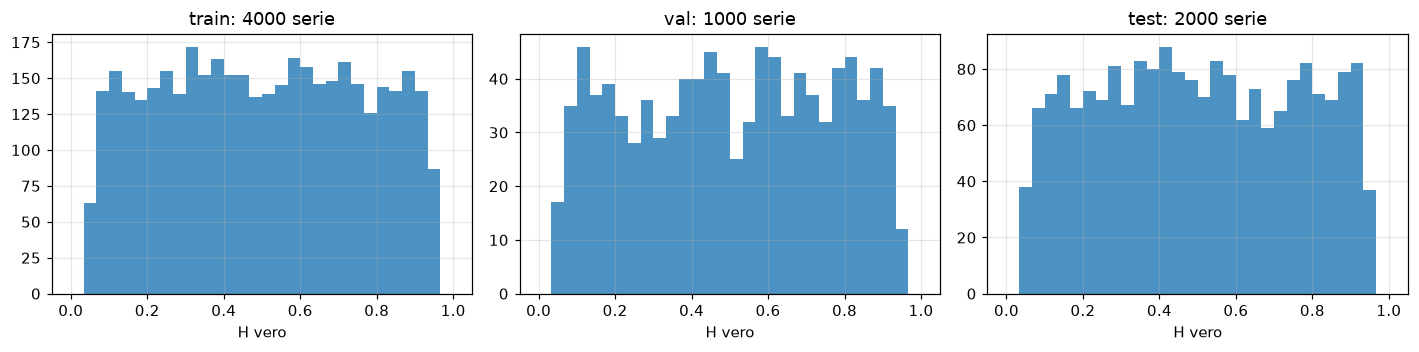

In [14]:
# Controlli sul dataset: nessuna serie ripetuta tra split, H uniforme, statistiche del fGn
hashes = {s: {hash(row.tobytes()) for row in d["X"]} for s, d in ds.items() if s in ("train", "val", "test")}
overlap = len(hashes["train"] & hashes["val"]) + len(hashes["train"] & hashes["test"]) + len(hashes["val"] & hashes["test"])
check("nessuna serie in comune tra train/val/test", overlap, "0", overlap == 0)

ks_p = {s: stats.kstest((ds[s]["H"] - 0.05) / 0.9, "uniform").pvalue for s in ("train", "val", "test")}
check("H uniforme in ogni split (test KS, p minimo)", f"{min(ks_p.values()):.3f}", "> 0.001", min(ks_p.values()) > 0.001)

m2 = (ds["train"]["X"].astype(np.float64) ** 2).mean(axis=1)   # media nota = 0: stimatore non distorto
check("fGn a varianza unitaria: media di <x^2> sul train", f"{m2.mean():.4f}", "1 ± 0.02", abs(m2.mean() - 1) < 0.02)

fig, axes = plt.subplots(1, 3, figsize=(13, 3.3))
for ax, s in zip(axes, ("train", "val", "test")):
    ax.hist(ds[s]["H"], bins=30, range=(0, 1), color="C0", alpha=0.8)
    ax.set(title=f"{s}: {len(ds[s]['H'])} serie", xlabel="H vero")
plt.tight_layout(); savefig("dataset_H"); plt.show()

*Nota sulla varianza per serie.* Il fGn ha varianza teorica 1, ma la varianza **campionaria** di una singola
serie (con la media stimata dalla serie stessa) è distorta verso il basso quando $H$ è grande. Infatti la media
campionaria è $W_H(N)/N$, con varianza $N^{2H}/N^2$, quindi

$$\mathbb E\big[s^2\big] = 1 - N^{2H-2}.$$

Per $H\to1$ le correlazioni a lungo raggio fanno "assorbire" alla media una parte grande della varianza.
Lo verifichiamo qui perché tornerà nella scelta della normalizzazione degli input (notebook 03):
normalizzare ogni serie con la propria media e deviazione standard non è un'operazione neutra rispetto ad $H$.

In [15]:
v = ds["train"]["X"].astype(np.float64).var(axis=1)     # varianza campionaria (media stimata)
Htr = ds["train"]["H"]
bins = np.linspace(0.05, 0.95, 10)
idx = np.digitize(Htr, bins)
centers = (bins[:-1] + bins[1:]) / 2
df_var = pd.DataFrame({
    "H (classe)": centers,
    "s^2 media": [v[idx == i].mean() for i in range(1, len(bins))],
    "attesa 1 - N^(2H-2)": [np.mean(1 - CFG["N"] ** (2 * Htr[idx == i] - 2)) for i in range(1, len(bins))],
    "SE": [v[idx == i].std(ddof=1) / np.sqrt((idx == i).sum()) for i in range(1, len(bins))],
})
df_var["z"] = (df_var["s^2 media"] - df_var["attesa 1 - N^(2H-2)"]) / df_var["SE"]
display(df_var.round(3).T)
zmax = df_var["z"].abs().max()
check("varianza campionaria per serie = 1 - N^(2H-2) (max|z| tra 9 classi di H)", f"{zmax:.2f}", "< 4", zmax < 4)

,0,1,2,3,4,5,6,7,8
H (classe),0.100,0.200,0.300,0.400,0.500,0.600,0.700,0.800,0.900
s^2 media,0.998,0.998,1.002,1.003,1.003,0.992,0.974,0.911,0.691
attesa 1 - N^(2H-2),1.000,1.000,1.000,0.999,0.998,0.993,0.974,0.913,0.690
SE,0.004,0.003,0.003,0.003,0.003,0.003,0.003,0.005,0.007
z,-0.483,-0.500,0.730,1.072,1.602,-0.101,-0.082,-0.354,0.192


OK      varianza campionaria per serie = 1 - N^(2H-2) (max|z| tra 9 classi di H): 1.60  (soglia < 4)


## 6. Riepilogo

In [16]:
df_checks = pd.DataFrame(CHECKS, columns=["verifica", "valore", "soglia", "esito"])
display(df_checks)
n_fail = (df_checks["esito"] != "OK").sum()
print(f"{len(df_checks) - n_fail}/{len(df_checks)} verifiche superate")
assert n_fail == 0, "Alcune verifiche sono fallite: non usare il dataset prima di averle capite."

,verifica,valore,soglia,esito
0,"autovalori Davies-Harte >= 0 (tutti H, tutti N)",2.5e-06,>= 0,OK
1,autocovarianza fGn: max|z| su lag 0-20 e 5 val...,2.18,< 4,OK
2,fBm: |pendenza - 2H| (max su 5 valori di H),0.0164,< 0.05,OK
3,fBm: max|z| di Var[W_H(t)] - t^2H (tutti t),2.77,< 5,OK
4,"ts2vg = definizione (NVG e HVG, 60 grafi di fB...",60/60,tutti,OK
5,HVG i.i.d.: max|z| di P(k) (gauss. e unif.),2.62,< 4,OK
6,HVG i.i.d.: max|z| di <k> vs formula esatta,0.98,< 4,OK
7,"NVG invariante per riscalamento, trend, affine",100%,~100%,OK
8,HVG invariante per riscalamento e trasformazio...,100%,100%,OK
9,HVG NON invariante per trend lineare (atteso: ...,0% identici,< 50%,OK


15/15 verifiche superate


**Cosa abbiamo stabilito**
- La simulazione Davies–Harte riproduce l'autocovarianza esatta del fGn e la legge di scala $t^{2H}$ del fBm:
  possiamo usare $H$ come verità nota.
- `ts2vg` coincide con la definizione dei grafi di visibilità; l'HVG del rumore i.i.d. segue la distribuzione
  esatta $\frac13(\frac23)^{k-2}$.
- Le invarianze sono confermate numericamente: NVG invariante per trasformazioni affini incluso il trend;
  HVG invariante per trasformazioni monotone ma **non** per il trend. È una correzione rispetto all'ipotesi
  iniziale ("il grafo di visibilità è invariante per trend"), che vale solo per la NVG.
- La varianza campionaria di una singola serie dipende da $H$: una normalizzazione per serie elimina
  un'informazione che, in linea di principio, contiene $H$ (da discutere nel notebook 03).

**Decisioni di questo notebook** (dettagli in `DECISION_LOG.md`): D-13 metodo di Davies–Harte;
D-14 salvare il fGn e derivare il fBm; D-15 split con seed indipendenti; D-16 set di robustezza;
D-17 soglie delle verifiche.